In [53]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [54]:
dfT = pd.read_csv('Tariff_plans_change.csv')
dfT.head()


,SUBSCRIBER_ID,TARIFF_PLAN_ID,START_DTTM,END_DTTM
0,1,2,2013-11-22 21:10:08,2017-03-11 14:24:17
1,1,3,2017-03-11 14:24:18,$null$
2,2,1,2016-02-05 16:36:34,2017-06-29 12:39:58
3,2,5,2017-06-29 12:39:59,$null$
4,3,1,2015-05-06 19:17:46,2017-04-14 12:00:59


In [55]:
dfS = pd.read_csv('Suspended.csv')
dfS.head()

,SUBSCRIBER_ID,START_DT,END_DT,STATUS
0,5195,2017-12-27,2017-12-27,Suspended
1,5198,2017-04-18,2017-04-18,Suspended
2,381,2017-04-18,2017-04-20,Suspended
3,3500,2017-12-21,$null$,Suspended
4,3302,2016-08-23,2016-09-07,Suspended


In [56]:
dfC = pd.read_csv('Charges.csv')
dfC.head()

,SUBSCRIBER_ID,BILL_MONTH,CHARGES
0,4741,2017-03-01,4.572
1,1754,2017-05-01,4.894
2,381,2017-01-01,6.670
3,5832,2016-12-01,4.299
4,5277,2017-03-01,1.610


In [57]:
dfT.replace(['$null$', 'null', 'NULL', 'None','NaT'], np.nan, inplace=True)
dfT.dropna(subset='START_DTTM',inplace = True)
dfT['END_DTTM'] = dfT['END_DTTM'].fillna(pd.Timestamp('2099-12-31'))

dfT['START_DTTM'] = pd.to_datetime(dfT['START_DTTM'])
dfT['END_DTTM'] = pd.to_datetime(dfT['END_DTTM'])


In [61]:
dfT = dfT.sort_values(by=['SUBSCRIBER_ID', 'START_DTTM'])
dfT.head()

,SUBSCRIBER_ID,TARIFF_PLAN_ID,START_DTTM,END_DTTM
0,1,2,2013-11-22 21:10:08,2017-03-11 14:24:17
1,1,3,2017-03-11 14:24:18,2099-12-31 00:00:00
2,2,1,2016-02-05 16:36:34,2017-06-29 12:39:58
3,2,5,2017-06-29 12:39:59,2099-12-31 00:00:00
4,3,1,2015-05-06 19:17:46,2017-04-14 12:00:59


In [62]:
# Создаем колонку со следующим тарифным планом для каждого абонента
dfT['NEXT_TARIFF'] = dfT.groupby('SUBSCRIBER_ID')['TARIFF_PLAN_ID'].shift(-1)

# Убираем строки, где NEXT_TARIFF пустой (это означает, что абонент остался на текущем тарифе и больше не менял его)
transitions = dfT.dropna(subset=['NEXT_TARIFF']).copy()

# Считаем частоту каждого перехода (из какого тарифа в какой)
transition_counts = (
    transitions.groupby(['TARIFF_PLAN_ID', 'NEXT_TARIFF'])
    .size()
    .reset_index(name='count')
)

# Сортируем по убыванию частоты и смотрим топ переходов
print(
    transition_counts.sort_values(by='count', ascending=False)
    .head(10)
    .to_string(index=False)
)

 TARIFF_PLAN_ID  NEXT_TARIFF  count
              3          5.0   2372
              1          5.0   1613
              4          5.0    528
              2          5.0    417
              1          4.0    378
              3          4.0    367
              2          4.0    158
              5          1.0     81
              5          3.0     75
              4          3.0     56


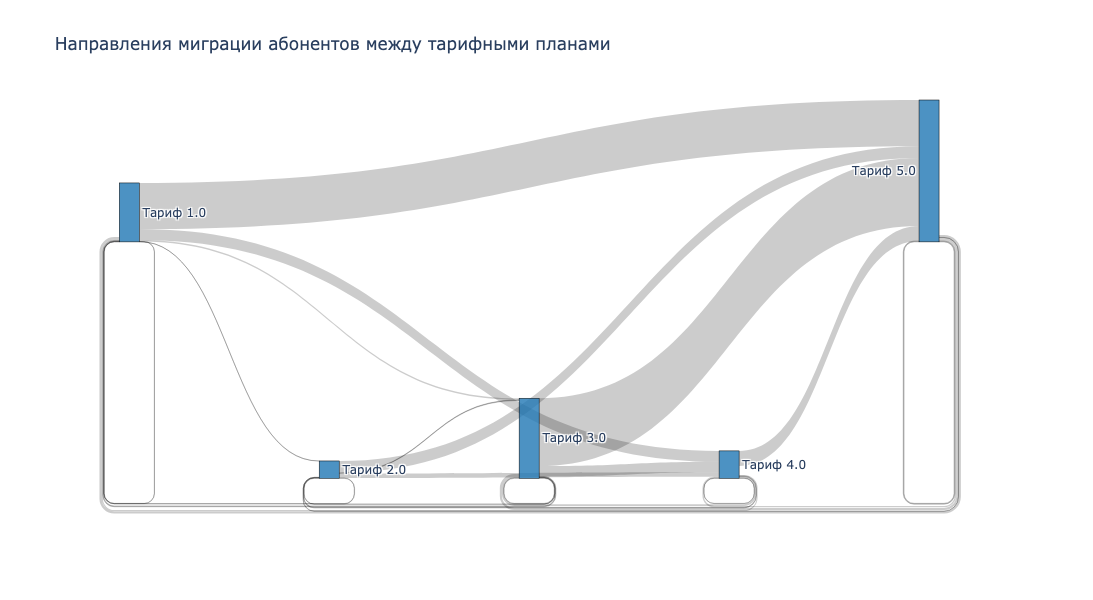

In [63]:
import plotly.graph_objects as go

tariffs = pd.unique(
    transition_counts[['TARIFF_PLAN_ID', 'NEXT_TARIFF']].values.ravel()
)
tariff_to_index = {tariff: i for i, tariff in enumerate(tariffs)}

source = transition_counts['TARIFF_PLAN_ID'].map(tariff_to_index)
target = transition_counts['NEXT_TARIFF'].map(tariff_to_index)
value = transition_counts['count']

fig = go.Figure(
    data=[
        go.Sankey(
            node=dict(
                pad=15,
                thickness=20,
                line=dict(color='black', width=0.5),
                label=[f'Тариф {t}' for t in tariffs],
                color='rgba(31, 119, 180, 0.8)',
            ),
            link=dict(
                source=source,
                target=target,
                value=value,
                label=[
                    f'{s} → {t} ({v})'
                    for s, t, v in zip(
                        transition_counts['TARIFF_PLAN_ID'],
                        transition_counts['NEXT_TARIFF'],
                        value,
                    )
                ],
            ),
        )
    ]
)

fig.update_layout(
    title_text='Направления миграции абонентов между тарифными планами',
    font_size=12,
    width=900,
    height=600,
)
fig.show()

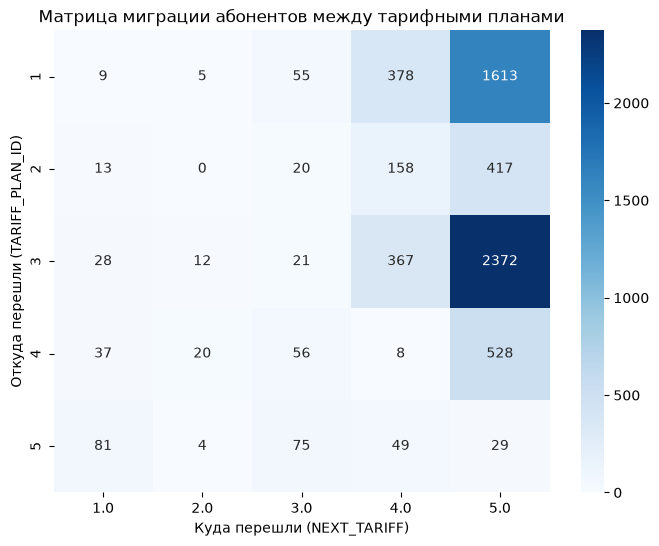

In [65]:
pivot_df = transition_counts.pivot_table(
    index='TARIFF_PLAN_ID',
    columns='NEXT_TARIFF',
    values='count',
    aggfunc='sum',
).fillna(0)

# 2. тепловая карта
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_df, annot=True, fmt='g', cmap='Blues', cbar=True)
plt.title('Матрица миграции абонентов между тарифными планами')
plt.xlabel('Куда перешли (NEXT_TARIFF)')
plt.ylabel('Откуда перешли (TARIFF_PLAN_ID)')
plt.show()


In [73]:
# 2. Преобразуем даты в datetime и сортируем по абоненту и времени
dfT['START_DTTM'] = pd.to_datetime(dfT['START_DTTM'])
dfT = dfT.sort_values(by=['SUBSCRIBER_ID', 'START_DTTM'])

# 3. Определяем следующий тариф и дату его начала для каждого абонента
dfT['NEXT_TARIFF'] = dfT.groupby('SUBSCRIBER_ID')['TARIFF_PLAN_ID'].shift(-1)
dfT['NEXT_START_DTTM'] = dfT.groupby('SUBSCRIBER_ID')['START_DTTM'].shift(-1)

# 4. Оставляем только те строки, где был реальный переход
transitions = dfT.dropna(subset=['NEXT_TARIFF']).copy()

# Месяц перехода (начало действия нового тарифа)
transitions['EVENT_MONTH'] = transitions['NEXT_START_DTTM'].dt.to_period(
    'M'
).dt.to_timestamp()

# 5. Приводим даты в чеках к формату datetime
dfC['BILL_MONTH'] = pd.to_datetime(dfC['BILL_MONTH'])

# Проверяем результат
transitions.head(3)

,SUBSCRIBER_ID,TARIFF_PLAN_ID,START_DTTM,END_DTTM,NEXT_TARIFF,NEXT_START_DTTM,EVENT_MONTH
0,1,2,2013-11-22 21:10:08,2017-03-11 14:24:17,3.0,2017-03-11 14:24:18,2017-03-01
2,2,1,2016-02-05 16:36:34,2017-06-29 12:39:58,5.0,2017-06-29 12:39:59,2017-06-01
4,3,1,2015-05-06 19:17:46,2017-04-14 12:00:59,5.0,2017-04-14 12:01:00,2017-04-01


In [74]:
# Шаг 2: Расчет расходов до и после смены тарифа
results = []

for idx, row in transitions.iterrows():
  sub_id = row['SUBSCRIBER_ID']
  event_month = row['EVENT_MONTH']
  old_tariff = row['TARIFF_PLAN_ID']
  new_tariff = row['NEXT_TARIFF']

  if pd.isna(event_month):
    continue

  # Период ДО: 3 месяца перед месяцем смены
  period_before = [
      event_month - pd.DateOffset(months=3),
      event_month - pd.DateOffset(months=2),
      event_month - pd.DateOffset(months=1),
  ]

  # Период ПОСЛЕ: 3 месяца после месяца смены
  period_after = [
      event_month + pd.DateOffset(months=1),
      event_month + pd.DateOffset(months=2),
      event_month + pd.DateOffset(months=3),
  ]

  # Фильтруем расходы конкретного абонента
  sub_charges = dfC[dfC['SUBSCRIBER_ID'] == sub_id]

  # Считаем средние расходы
  charges_before = sub_charges[
      sub_charges['BILL_MONTH'].isin(period_before)
  ]['CHARGES'].mean()
  charges_after = sub_charges[sub_charges['BILL_MONTH'].isin(period_after)][
      'CHARGES'
  ].mean()

  if not pd.isna(charges_before) and not pd.isna(charges_after):
    results.append({
        'SUBSCRIBER_ID': sub_id,
        'FROM_TARIFF': old_tariff,
        'TO_TARIFF': new_tariff,
        'AVG_BEFORE': charges_before,
        'AVG_AFTER': charges_after,
        'DIFF': charges_after - charges_before,
    })

# Переводим в DataFrame
df_res = pd.DataFrame(results)

# Группируем по направлениям смен тарифов
summary_diff = (
    df_res.groupby(['FROM_TARIFF', 'TO_TARIFF'])[['AVG_BEFORE', 'AVG_AFTER', 'DIFF']]
    .mean()
    .reset_index()
)

print('Результаты по направлениям миграции:')
print(summary_diff.to_string(index=False))

Результаты по направлениям миграции:
 FROM_TARIFF  TO_TARIFF  AVG_BEFORE  AVG_AFTER      DIFF
           1        1.0    7.776810   6.657667 -1.119143
           1        2.0    5.128467   3.989200 -1.139267
           1        3.0   11.287133  10.026624 -1.260509
           1        4.0    6.443156   4.590384 -1.852773
           1        5.0    9.036344   6.965394 -2.070950
           2        1.0    7.857000   6.910051 -0.946949
           2        3.0   12.844017   9.495733 -3.348283
           2        4.0    6.013911   4.260503 -1.753408
           2        5.0    8.233916   6.599886 -1.634030
           3        1.0    8.769012   7.870810 -0.898202
           3        2.0    9.583917  12.377389  2.793472
           3        3.0    9.927267   8.577833 -1.349433
           3        4.0    8.154639   5.742567 -2.412072
           3        5.0    9.275933   7.099270 -2.176663
           4        1.0    6.044613   6.805009  0.760396
           4        2.0    5.275917   6.077283  0.8

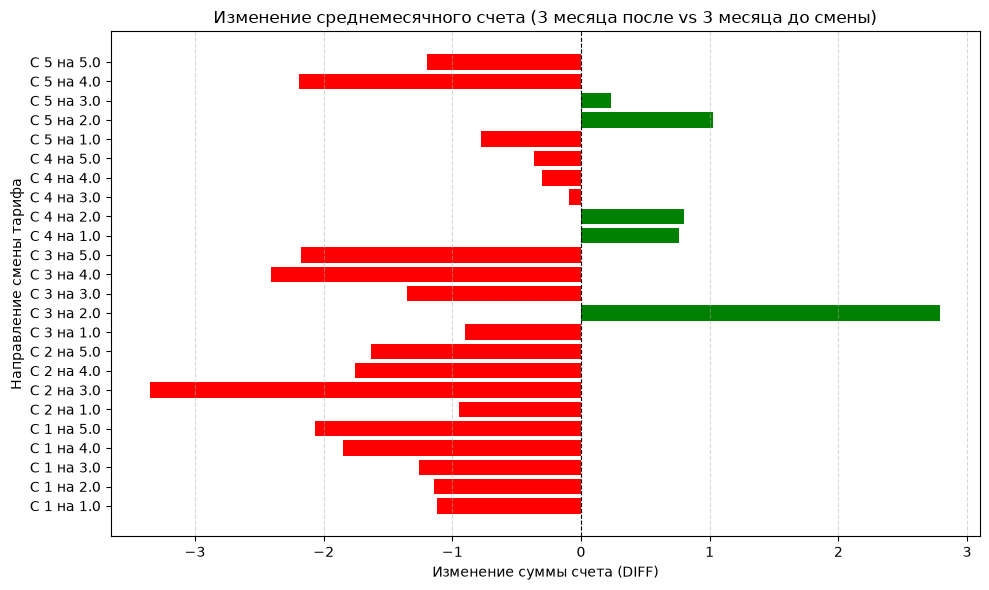

In [75]:
import matplotlib.pyplot as plt

# Шаг 3: Визуализация изменений среднемесячного счета
plt.figure(figsize=(10, 6))

# Формируем читаемое название направления (например, "С 1.0 на 2.0")
summary_diff['ROUTE'] = (
    'С '
    + summary_diff['FROM_TARIFF'].astype(str)
    + ' на '
    + summary_diff['TO_TARIFF'].astype(str)
)

# Задаем цвета: зеленый для роста, красный для уменьшения
colors = ['red' if x < 0 else 'green' for x in summary_diff['DIFF']]

# Строим горизонтальную столбчатую диаграмму
plt.barh(summary_diff['ROUTE'], summary_diff['DIFF'], color=colors)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')

plt.title(
    'Изменение среднемесячного счета (3 месяца после vs 3 месяца до смены)'
)
plt.xlabel('Изменение суммы счета (DIFF)')
plt.ylabel('Направление смены тарифа')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [76]:
dfS.replace(['$null$', 'null', 'NULL', 'None'], np.nan, inplace=True)
dfS['START_DT'] = pd.to_datetime(dfS['START_DT'])
dfS['END_DT'] = dfS['END_DT'].fillna('2099-12-31')
dfS['END_DT'] = pd.to_datetime(dfS['END_DT'])

In [77]:
results_suspend = []

for idx, row in transitions.iterrows():
  sub_id = row['SUBSCRIBER_ID']
  event_month = row['EVENT_MONTH']
  old_tariff = row['TARIFF_PLAN_ID']
  new_tariff = row['NEXT_TARIFF']

  if pd.isna(event_month):
    continue

  # Периоды по 3 месяца до и после
  period_before_months = [
      event_month - pd.DateOffset(months=3),
      event_month - pd.DateOffset(months=2),
      event_month - pd.DateOffset(months=1),
  ]

  period_after_months = [
      event_month + pd.DateOffset(months=1),
      event_month + pd.DateOffset(months=2),
      event_month + pd.DateOffset(months=3),
  ]

  # Фильтруем блокировки конкретного абонента
  sub_susp = dfS[dfS['SUBSCRIBER_ID'] == sub_id]


  # Функция для подсчета дней блокировки, попавших в целевые месяцы
  def get_suspension_days(susp_df, target_months):
    total_days = 0
    for m in target_months:
      m_start = m
      m_end = m + pd.DateOffset(months=1) - pd.Timedelta(days=1)
      for _, s_row in susp_df.iterrows():
        s_start = max(s_row['START_DT'], m_start)
        s_end = min(s_row['END_DT'], m_end)
        if s_start <= s_end:
          total_days += (s_end - s_start).days + 1
    return total_days


  days_before = get_suspension_days(sub_susp, period_before_months)
  days_after = get_suspension_days(sub_susp, period_after_months)

  results_suspend.append({
      'SUBSCRIBER_ID': sub_id,
      'FROM_TARIFF': old_tariff,
      'TO_TARIFF': new_tariff,
      'DAYS_BEFORE': days_before,
      'DAYS_AFTER': days_after,
      'DIFF_DAYS': days_after - days_before,
  })

# Переводим в DataFrame и группируем по направлениям
df_sus_res = pd.DataFrame(results_suspend)
summary_sus = (
    df_sus_res.groupby(['FROM_TARIFF', 'TO_TARIFF'])[
        ['DAYS_BEFORE', 'DAYS_AFTER', 'DIFF_DAYS']
    ]
    .mean()
    .reset_index()
)

print('Изменение уровня блокировок по направлениям миграции:')
print(summary_sus.to_string(index=False))

Изменение уровня блокировок по направлениям миграции:
 FROM_TARIFF  TO_TARIFF  DAYS_BEFORE  DAYS_AFTER  DIFF_DAYS
           1        1.0     0.000000    0.000000   0.000000
           1        2.0     0.000000    0.000000   0.000000
           1        3.0     0.509091    1.145455   0.636364
           1        4.0     4.314815    2.460317  -1.854497
           1        5.0     1.203968    0.816491  -0.387477
           2        1.0     0.000000    3.384615   3.384615
           2        3.0     0.350000    0.650000   0.300000
           2        4.0     0.107595    3.930380   3.822785
           2        5.0     0.304556    0.484412   0.179856
           3        1.0     1.857143    0.250000  -1.607143
           3        2.0     8.000000    0.833333  -7.166667
           3        3.0     0.000000    0.000000   0.000000
           3        4.0     7.021798    4.555858  -2.465940
           3        5.0     1.380270    0.841484  -0.538786
           4        1.0     0.945946    4.1621

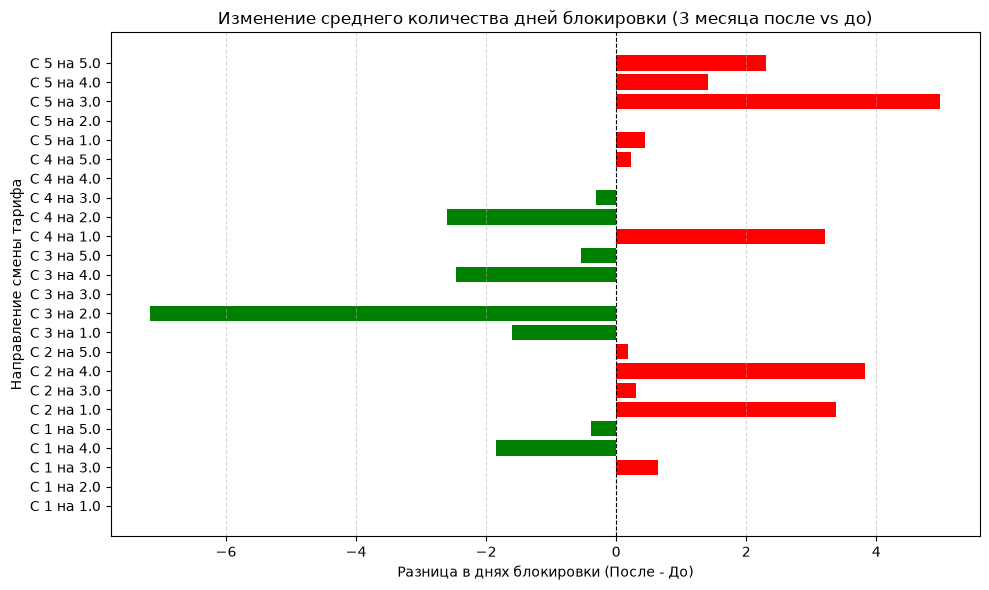

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

summary_sus['ROUTE'] = (
    'С '
    + summary_sus['FROM_TARIFF'].astype(str)
    + ' на '
    + summary_sus['TO_TARIFF'].astype(str)
)

# Красный — если блокировок стало больше (ухудшение), зеленый — если меньше (улучшение)
colors = ['red' if x > 0 else 'green' for x in summary_sus['DIFF_DAYS']]

plt.barh(summary_sus['ROUTE'], summary_sus['DIFF_DAYS'], color=colors)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')

plt.title(
    'Изменение среднего количества дней блокировки (3 месяца после vs до)'
)
plt.xlabel('Разница в днях блокировки (После - До)')
plt.ylabel('Направление смены тарифа')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()